Sin embargo, en los anteriores dos proyectos pudimos modelar precios de activos al final del año, al siguiente día utilizando suposiciones e incluso datos reales, pero en el mercado cotidiano esto no ocurre de esta manera, es decir si la bolsa en estos instantes se desplomará seguramente el precio de varios activos se caeria, o viceversa, si los valores de algún indice económico subieran entonces seguramente el precio de varios activos también lo harían, es decir los activos en la vida real estan correlacionados. 

Para trabajar con activos correlacionados podemos seguir trabajando con simulaciones e incluso con datos reales pero ahora estas deberían de estar basadas en simulaciones multivariadas, descarguemos la info de dos activos y veamos su relación para entender mejor este concepto.

Los índices que vamos a utilizar son "SPY" y "QQQ" los cuales explican lo siguiente:

SPY: Es un ETF que sigue al: S&P 500 que son las 500 empresas grandes más importantes de EE.UU.

QQQ: ETF que sigue al: Nasdaq-100 que son las 100 empresas no financieras más grandes del Nasdaq.

In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

# Descargar datos históricos
tickers = ["SPY", "QQQ"]

datos = yf.download(
    tickers,
    start="2015-01-01",
    end="2025-01-01",
    progress=False
)

# Obtener precios de cierre
close = datos["Close"]

# Mostrar primeras filas
print(close.head())



Ticker            QQQ         SPY
Date                             
2015-01-02  94.665085  170.125000
2015-01-05  93.276474  167.052582
2015-01-06  92.025795  165.479141
2015-01-07  93.212059  167.541199
2015-01-08  94.996117  170.514236


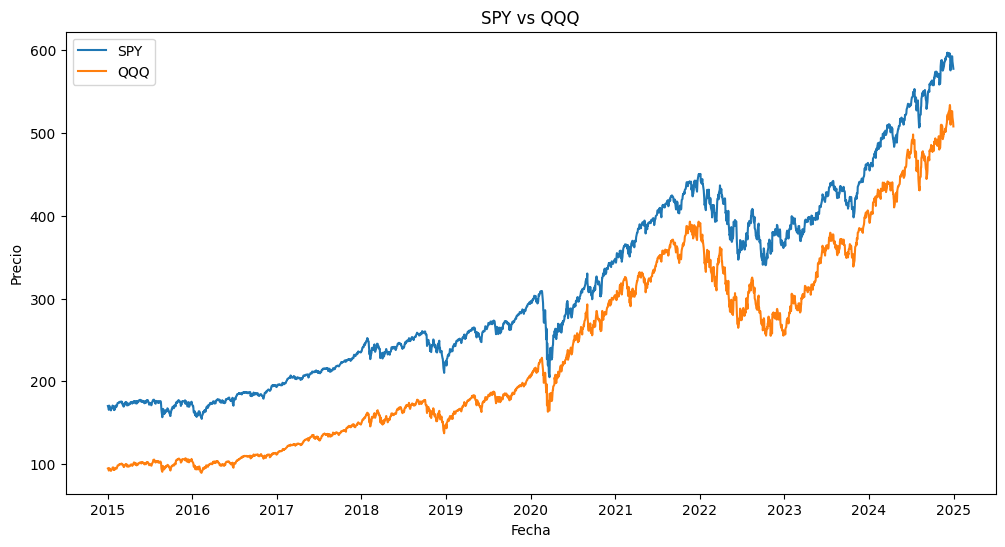

In [40]:
# =========================
# GRÁFICA DE PRECIOS
# =========================

plt.figure(figsize=(12,6))

plt.plot(close.index, close["SPY"], label="SPY")
plt.plot(close.index, close["QQQ"], label="QQQ")

plt.title("SPY vs QQQ")
plt.xlabel("Fecha")
plt.ylabel("Precio")

plt.legend()

plt.show()



Correlación SPY-QQQ: 0.9293


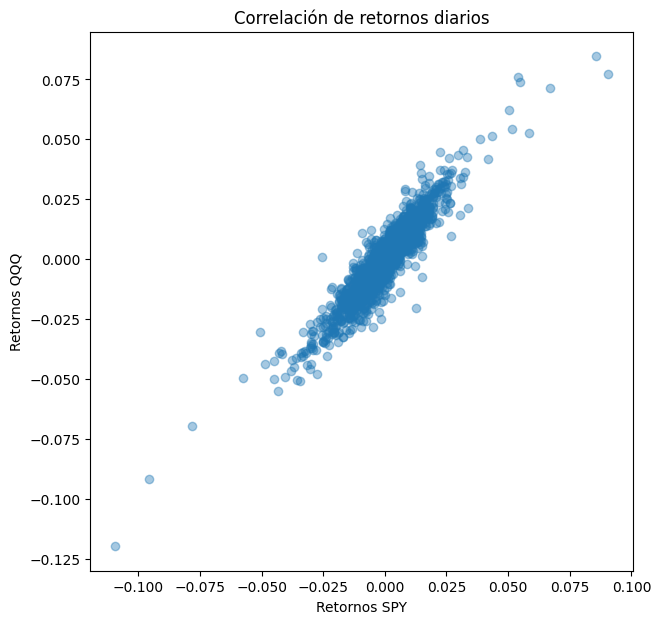

In [41]:
# =========================
# RETORNOS DIARIOS
# =========================

retornos = close.pct_change().dropna()

# =========================
# CORRELACIÓN
# =========================

correlacion = retornos["SPY"].corr(retornos["QQQ"])

print(f"Correlación SPY-QQQ: {correlacion:.4f}")

# =========================
# SCATTERPLOT DE RETORNOS
# =========================

plt.figure(figsize=(7,7))

plt.scatter(
    retornos["SPY"],
    retornos["QQQ"],
    alpha=0.4
)

plt.title("Correlación de retornos diarios")
plt.xlabel("Retornos SPY")
plt.ylabel("Retornos QQQ")

plt.show()



Estos son los comportamientos esperados de dos índices los cuales están tan fuertemente correlacionados, ahora intentemos simularlos con una normal multivariada ejjeje, sin embargo tomemos 6 meses antes de los datos que tenemos para ver si las proyecciones son consistentes con lo observado. 

In [42]:
# =========================================
# 1. DESCARGAR DATOS
# =========================================

tickers = ["SPY", "QQQ"]

datos = yf.download(
    tickers,
    start="2021-01-01",
    end="2026-01-01",
    progress=False
)["Close"]

# Eliminar faltantes
datos = datos.dropna()


# =========================================
# 2. DEFINIR VENTANAS
# =========================================

# Año y medio para calibrar
train = datos.loc["2021-01-01":"2025-06-30"]

# 6 meses reales posteriores
test = datos.loc["2025-07-01":"2026-01-01"]

retornos = train.pct_change().dropna()

# Media vectorial
mu = retornos.mean().values

# Matriz de covarianza
cov = retornos.cov().values


# =========================================
# 4. PARÁMETROS DE SIMULACIÓN
# =========================================

dias = len(test)

simulaciones = 1000

# Precios iniciales
S0 = train.iloc[-1].values

Preparados los datos hacemos la simulación

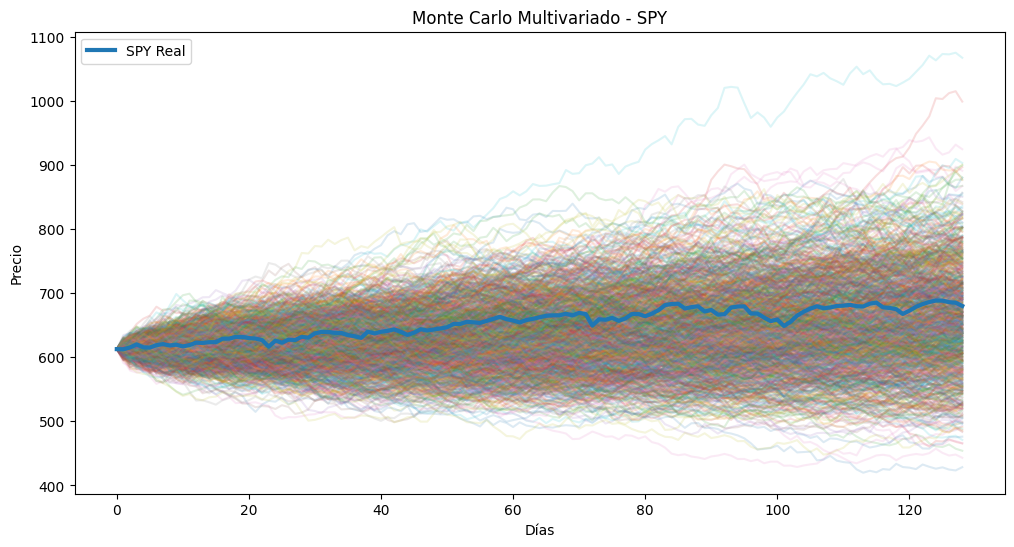

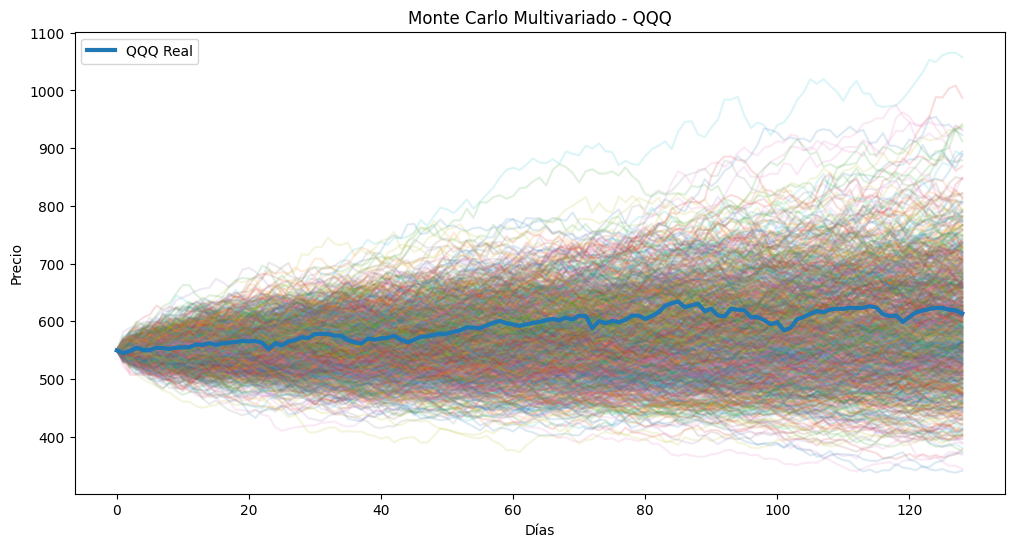

In [43]:
# =========================================
# 5. MONTE CARLO MULTIVARIADO
# =========================================

simulaciones_spy = []
simulaciones_qqq = []
np.random.seed(123)

for _ in range(simulaciones):

    precios = np.zeros((dias + 1, 2))

    precios[0] = S0

    for t in range(1, dias + 1):

        # Shocks correlacionados
        Z = np.random.multivariate_normal(mu, cov)

        # Evolución GBM discreta
        precios[t] = precios[t - 1] * (1 + Z)

    simulaciones_qqq.append(precios[:,0])
    simulaciones_spy.append(precios[:,1])

# =========================================
# 6. GRAFICAR SPY
# =========================================

plt.figure(figsize=(12,6))

# Simulaciones
for sim in simulaciones_spy:
    plt.plot(sim, alpha=0.15)

# Trayectoria real
plt.plot(
    range(dias + 1),
    np.concatenate([[S0[1]], test["SPY"].values]),
    linewidth=3,
    label="SPY Real"
)

plt.title("Monte Carlo Multivariado - SPY")
plt.xlabel("Días")
plt.ylabel("Precio")

plt.legend()

plt.show()

# =========================================
# 7. GRAFICAR QQQ
# =========================================

plt.figure(figsize=(12,6))

# Simulaciones
for sim in simulaciones_qqq:
    plt.plot(sim, alpha=0.15)

# Trayectoria real
plt.plot(
    range(dias + 1),
    np.concatenate([[S0[0]], test["QQQ"].values]),
    linewidth=3,
    label="QQQ Real"
)

plt.title("Monte Carlo Multivariado - QQQ")
plt.xlabel("Días")
plt.ylabel("Precio")

plt.legend()

plt.show()


In [45]:
# =========================================
# 8. VALORES FINALES
# =========================================

spy_finales = [sim[-1] for sim in simulaciones_spy]
qqq_finales = [sim[-1] for sim in simulaciones_qqq]

print("SPY real inicial", train["SPY"].iloc[-1])
print("SPY real final:", test["SPY"].iloc[-1])
print("SPY promedio simulado:", np.mean(spy_finales))

print()

print("QQQ real inicial", train["QQQ"].iloc[-1])
print("QQQ real final:", test["QQQ"].iloc[-1])
print("QQQ promedio simulado:", np.mean(qqq_finales))

SPY real inicial 612.6533203125
SPY real final: 680.062744140625
SPY promedio simulado: 660.650459718193

QQQ real inicial 549.5992431640625
QQQ real final: 613.536376953125
QQQ promedio simulado: 596.3429069779742


Demos una trayectoria promedio de la simulación de Monte Carlo para poderla comparar puntualmente con la observada en el conjunto de prueba (6 meses)

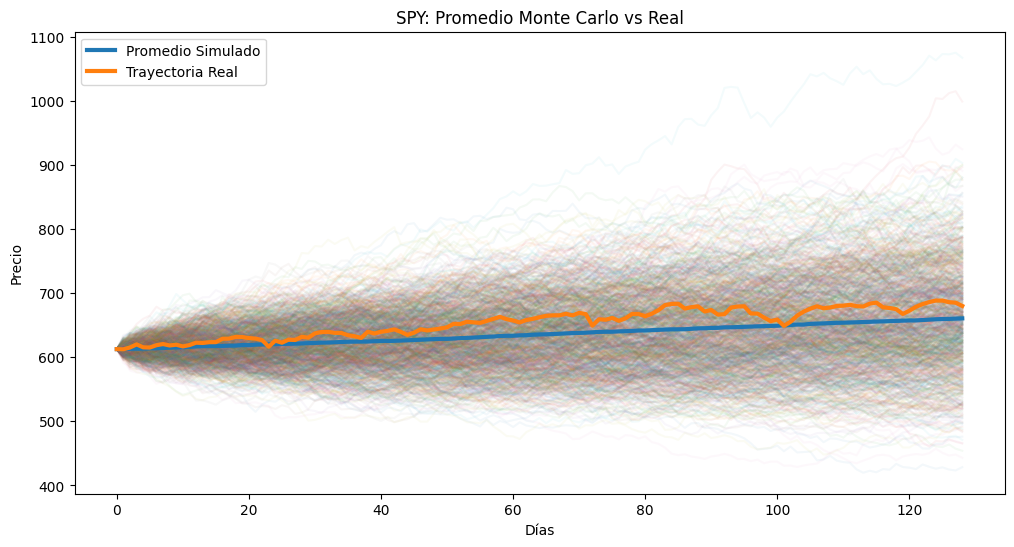

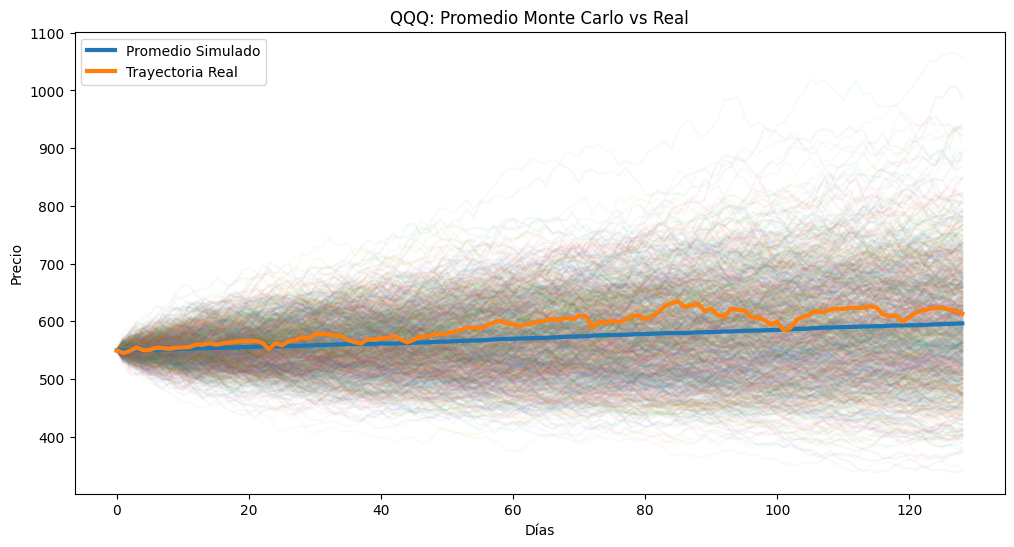

In [46]:
# Convertir simulaciones a array
sim_spy_array = np.array(simulaciones_spy)

# Promedio diario
promedio_spy = sim_spy_array.mean(axis=0)

# Trayectoria real
real_spy = np.concatenate([[S0[1]], test["SPY"].values])

# Graficar
plt.figure(figsize=(12,6))

# Simulaciones individuales
for sim in simulaciones_spy:
    plt.plot(sim, alpha=0.05)

# Trayectoria promedio
plt.plot(
    promedio_spy,
    linewidth=3,
    label="Promedio Simulado"
)

# Trayectoria real
plt.plot(
    real_spy,
    linewidth=3,
    label="Trayectoria Real"
)

plt.title("SPY: Promedio Monte Carlo vs Real")
plt.xlabel("Días")
plt.ylabel("Precio")

plt.legend()

plt.show()

#---------
# Convertir simulaciones a array
sim_qqq_array = np.array(simulaciones_qqq)

# Promedio diario
promedio_qqq = sim_qqq_array.mean(axis=0)

# Trayectoria real
real_qqq = np.concatenate([[S0[0]], test["QQQ"].values])

# Graficar
plt.figure(figsize=(12,6))

# Simulaciones individuales
for sim in simulaciones_qqq:
    plt.plot(sim, alpha=0.05)

# Trayectoria promedio
plt.plot(
    promedio_qqq,
    linewidth=3,
    label="Promedio Simulado"
)

# Trayectoria real
plt.plot(
    real_qqq,
    linewidth=3,
    label="Trayectoria Real"
)

plt.title("QQQ: Promedio Monte Carlo vs Real")
plt.xlabel("Días")
plt.ylabel("Precio")

plt.legend()

plt.show()

Esta simulación de ambos activos siguen siendo muy buenas, sin embargo, podría pensarse que se debe a la fuerte corrlación que hay entre los activos, por lo que repetiremos el proceso pero ahora para activos que no estan tan fuertemente correlacionados.

---

Continuando ahora con la simulación:

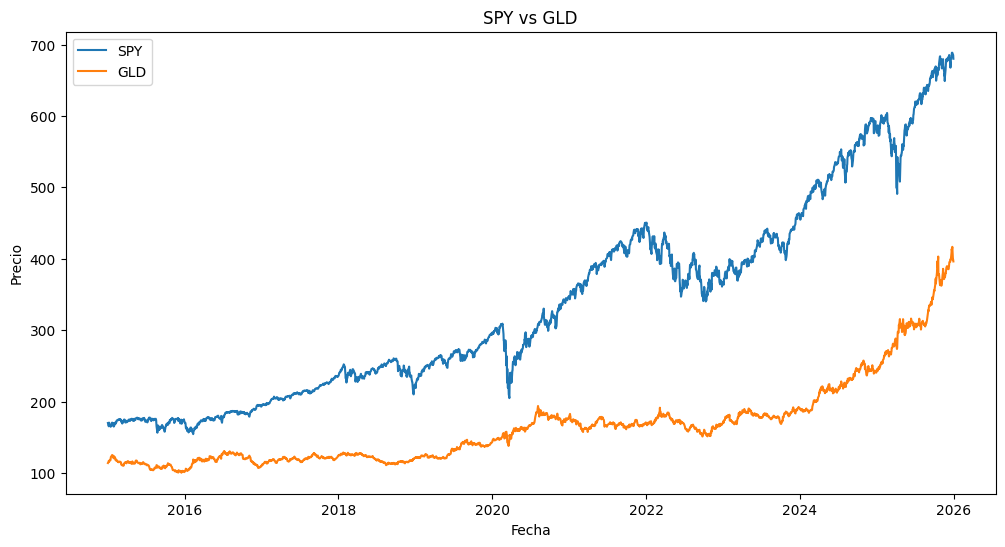

In [54]:
# Descargar datos históricos
tickers = ["SPY", "GLD"]

datos = yf.download(
    tickers,
    start="2015-01-01",
    end="2026-01-01",
    progress=False
)

# Obtener precios de cierre
close = datos["Close"]

# =========================
# GRÁFICA DE PRECIOS
# =========================

plt.figure(figsize=(12,6))

plt.plot(close.index, close["SPY"], label="SPY")
plt.plot(close.index, close["GLD"], label="GLD")

plt.title("SPY vs GLD")
plt.xlabel("Fecha")
plt.ylabel("Precio")

plt.legend()

plt.show()



Correlación SPY-GLD: 0.0442


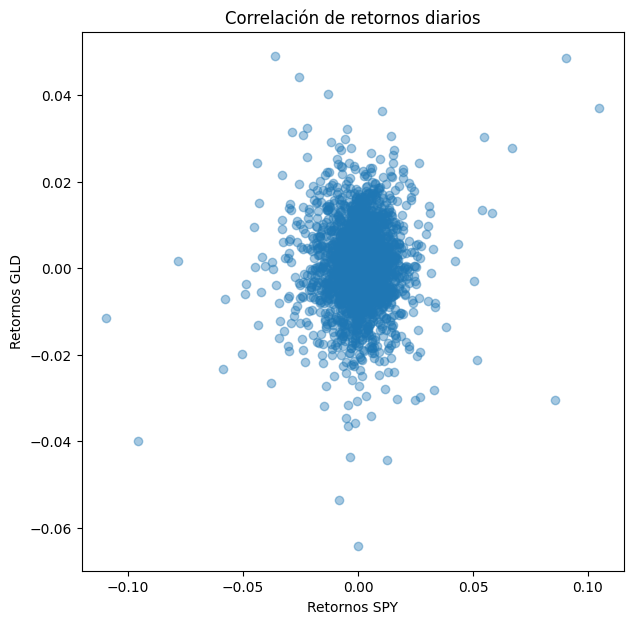

In [55]:
# =========================
# RETORNOS DIARIOS
# =========================

retornos = close.pct_change().dropna()

# =========================
# CORRELACIÓN
# =========================

correlacion = retornos["SPY"].corr(retornos["GLD"])

print(f"Correlación SPY-GLD: {correlacion:.4f}")

# =========================
# SCATTERPLOT DE RETORNOS
# =========================

plt.figure(figsize=(7,7))

plt.scatter(
    retornos["SPY"],
    retornos["GLD"],
    alpha=0.4
)

plt.title("Correlación de retornos diarios")
plt.xlabel("Retornos SPY")
plt.ylabel("Retornos GLD")

plt.show()



In [57]:
# =========================================
# 1. DESCARGAR DATOS
# =========================================

tickers = ["SPY", "GLD"]

datos = yf.download(
    tickers,
    start="2021-01-01",
    end="2026-01-01",
    progress=False
)["Close"]

# Eliminar faltantes
datos = datos.dropna()


# =========================================
# 2. DEFINIR VENTANAS
# =========================================

# Año y medio para calibrar
train = datos.loc["2021-01-01":"2025-07-31"]

# 6 meses reales posteriores
test = datos.loc["2025-08-01":"2026-01-01"]

retornos = train.pct_change().dropna()

# Media vectorial
mu = retornos.mean().values

# Matriz de covarianza
cov = retornos.cov().values


# =========================================
# 4. PARÁMETROS DE SIMULACIÓN
# =========================================

dias = len(test)

simulaciones = 1000

# Precios iniciales
S0 = train.iloc[-1].values

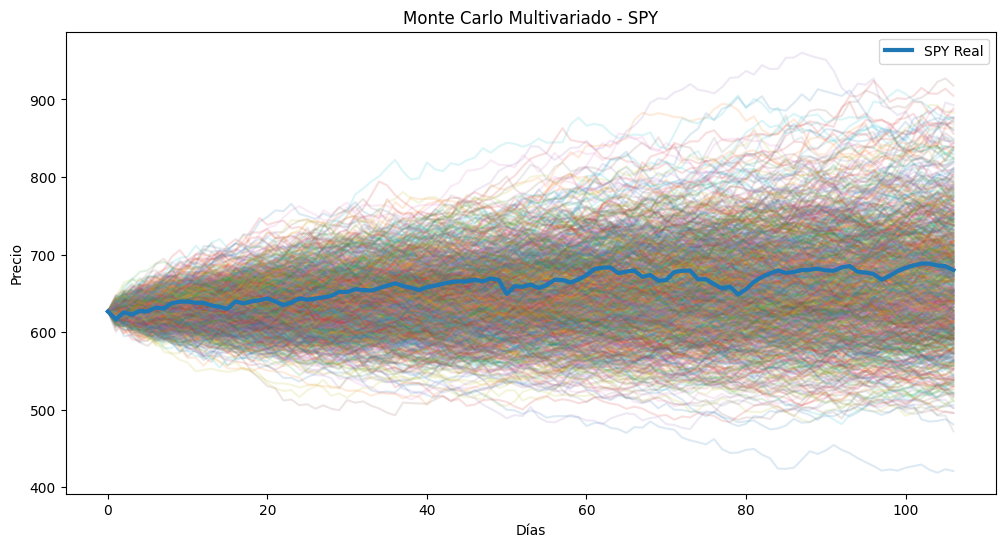

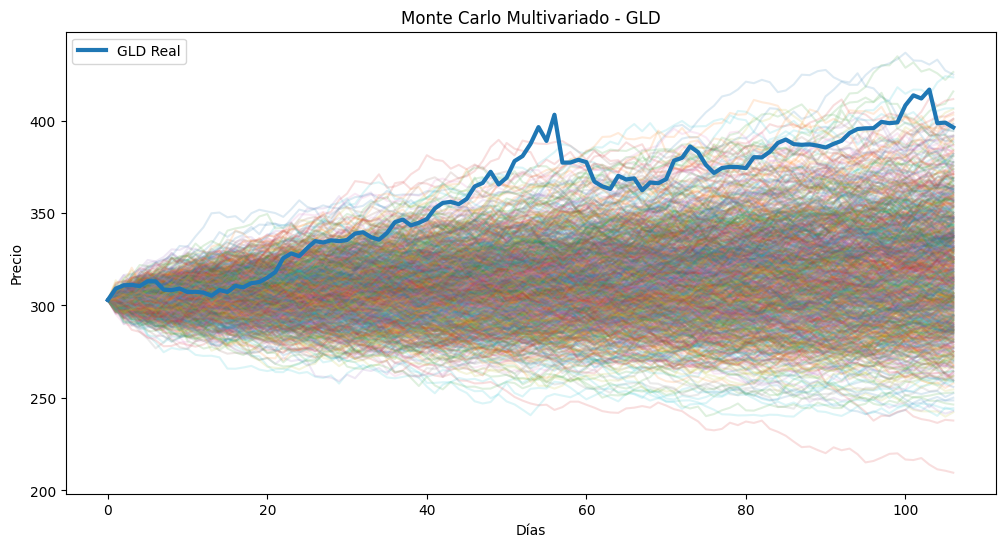

In [58]:
# =========================================
# 5. MONTE CARLO MULTIVARIADO
# =========================================

simulaciones_spy = []
simulaciones_gld = []
np.random.seed(123)

for _ in range(simulaciones):

    precios = np.zeros((dias + 1, 2))

    precios[0] = S0

    for t in range(1, dias + 1):

        # Shocks correlacionados
        Z = np.random.multivariate_normal(mu, cov)

        # Evolución GBM discreta
        precios[t] = precios[t - 1] * (1 + Z)

    simulaciones_gld.append(precios[:,0])
    simulaciones_spy.append(precios[:,1])

# =========================================
# 6. GRAFICAR SPY
# =========================================

plt.figure(figsize=(12,6))

# Simulaciones
for sim in simulaciones_spy:
    plt.plot(sim, alpha=0.15)

# Trayectoria real
plt.plot(
    range(dias + 1),
    np.concatenate([[S0[1]], test["SPY"].values]),
    linewidth=3,
    label="SPY Real"
)

plt.title("Monte Carlo Multivariado - SPY")
plt.xlabel("Días")
plt.ylabel("Precio")

plt.legend()

plt.show()

# =========================================
# 7. GRAFICAR GLD
# =========================================

plt.figure(figsize=(12,6))

# Simulaciones
for sim in simulaciones_gld:
    plt.plot(sim, alpha=0.15)

# Trayectoria real
plt.plot(
    range(dias + 1),
    np.concatenate([[S0[0]], test["GLD"].values]),
    linewidth=3,
    label="GLD Real"
)

plt.title("Monte Carlo Multivariado - GLD")
plt.xlabel("Días")
plt.ylabel("Precio")

plt.legend()

plt.show()


In [59]:
# =========================================
# 8. VALORES FINALES
# =========================================

spy_finales = [sim[-1] for sim in simulaciones_spy]
gld_finales = [sim[-1] for sim in simulaciones_gld]

print("SPY real inicial", train["SPY"].iloc[-1])
print("SPY real final:", test["SPY"].iloc[-1])
print("SPY promedio simulado:", np.mean(spy_finales))

print()

print("GLD real inicial", train["GLD"].iloc[-1])
print("GLD real final:", test["GLD"].iloc[-1])
print("GLD promedio simulado:", np.mean(gld_finales))

SPY real inicial 626.763671875
SPY real final: 680.062744140625
SPY promedio simulado: 666.9224620976805

GLD real inicial 302.9599914550781
GLD real final: 396.30999755859375
GLD promedio simulado: 320.6811424697868


Claramente notamos un fuerte problema en la predicción del precio del activo relacionado al ORO, sin embargo, esto ocurre más por el comportamiento volatil en el periodo de prueba del mismo, podríamos aplicar otro tipo de modelos únicamente a este activo, tales como ARCH, GARCH o GARCH Multivariado (consideramos que la volatilidad cambia con el tiempo). Algo que is podríamos entender el algo que se llama correlación dinámica o rolling correalation que es una serie de como va cambiando la correlación a lo largo del tiempo. 

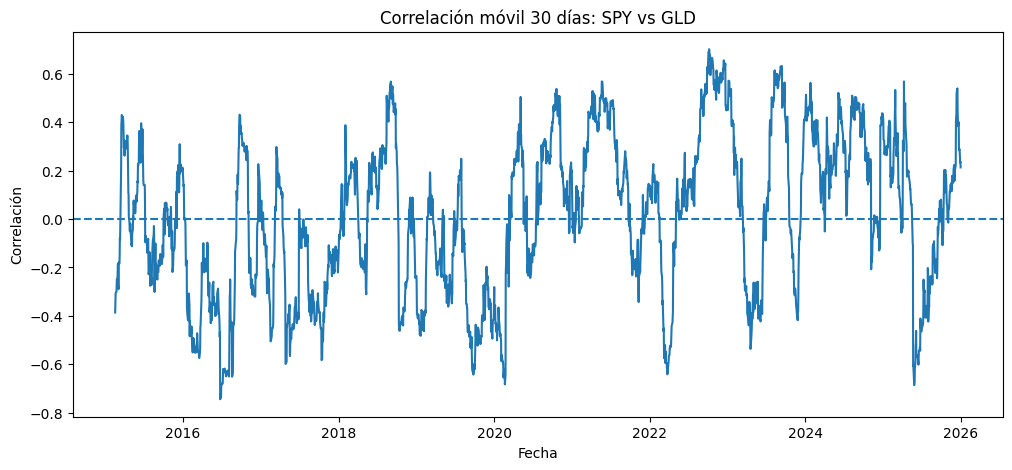

In [61]:

datos = yf.download(
    ["SPY", "GLD"],
    start="2015-01-01",
    end="2026-01-01",
    progress=False
)["Close"]

# Retornos
retornos = datos.pct_change().dropna()

# Correlación móvil de 30 días
rolling_corr = (
    retornos["SPY"]
    .rolling(window=30)
    .corr(retornos["GLD"])
)

# Graficar
plt.figure(figsize=(12,5))

plt.plot(rolling_corr)

plt.title("Correlación móvil 30 días: SPY vs GLD")
plt.xlabel("Fecha")
plt.ylabel("Correlación")

plt.axhline(0, linestyle="--")

plt.show()

Claramente parece ser que esta serie de tiempo es estacionaria y que se podría modelar para dar paso a un GARCH y hacer una modelación con heterocedasticidad c: